# How the scheduler chooses what to observe

`m4opt schedule` turns a gravitational-wave localization into an observing
plan. It does not tile the 90% credible region: it solves a mixed-integer
program that maximizes the probability of detecting the kilonova within the
time available, and the two are not the same thing.

This notebook takes one schedule apart. Every quantity it draws is computed
with the M4OPT functions the scheduler itself used, read back from the
schedule's own metadata, so nothing here is a reconstruction of what the
optimizer might have done.

The event is O5a/597 of the PixelPop observing scenarios: a 2.04 + 1.85
$M_\odot$ binary neutron star at 184 Mpc, seen by LIGO Hanford and Virgo at a
network SNR of 14.5. Its sky map and the two schedules are in
`results/pixelpop/example/O5a/`.

In [1]:
import warnings

# Set before the imports below, which emit a deprecation warning from
# reproject and a redirection notice from LAL.
warnings.filterwarnings("ignore")

from pathlib import Path  # noqa: E402

import ligo.skymap.plot  # noqa: F401  (registers the "astro ..." projections)
import numpy as np
from astropy import units as u
from astropy.coordinates import SkyCoord
from m4opt.fov import footprint
from matplotlib import pyplot as plt

from ultrasat_gw_followup.analysis.plan import (  # noqa: E402
    Plan,
    Products,
    auto_zoom,
    field_of_regard,
)

ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file()
)
EXAMPLE_RUN, EXAMPLE_EVENT = "O5a", 597
EXAMPLE = ROOT / "results/pixelpop/example" / EXAMPLE_RUN
SKYMAP = EXAMPLE / f"{EXAMPLE_EVENT}.fits"

plan = Plan.read(EXAMPLE / f"{EXAMPLE_EVENT}_allsky.ecsv", skymap=str(SKYMAP))
products = Products.compute(plan)

center, radius = auto_zoom(plan)
pixel_area = products.hpx.pixel_area.to_value(u.deg**2)

meta = plan.obs.meta
print(f"mission      {plan.mission.name}, {plan.mission.fov.width} field of view")
print(f"sky grid     {plan.skygrid}, {len(plan.candidates)} candidate pointings")
print(f"window       {plan.delay} to {plan.deadline} after the merger")
print(f"depth        kilonova at M = {plan.absmag_mean}, SNR {plan.snr} in {plan.bandpass}")
print(f"objective    {meta['objective_value']:.4f} "
      f"(best bound {meta['best_bound']:.4f}: {meta['solution_status']})")

mission      ultrasat, 14.28 deg field of view
sky grid     allsky, 361 candidate pointings
window       15.0 min to 6.0 h after the merger
depth        kilonova at M = -16.0, SNR 5.0 in NUV
objective    0.9207 (best bound 0.9207: integer optimal solution)


## 1. The localization

This is what reaches observers: a posterior probability density over
direction, distributed as a multi-order HEALPix map. Drawn over the whole sky
the way the LIGO-Virgo-KAGRA alerts present it, with the 50% and 90% credible
contours, it is two thin arcs rather than a compact patch.

That shape comes from the network. Only Hanford and Virgo saw this event, so
the direction is constrained almost entirely by the difference in arrival time
between the two sites. A given delay does not single out a point. It singles
out every direction making the same angle with the line joining the two
detectors, and that is a circle on the sky, centred on that line. The two arcs
are not two rings: they are the portions of one circle where the measured
amplitudes remain consistent, the antenna patterns having suppressed the rest.
How wide that band is depends on how well the arrival time was measured.

Detectors do not add arcs, they add baselines. Three sites give two
independent delays, and two circles meet in a pair of points mirrored through
the plane of the three detectors. The result is a compact patch, sometimes
with a fainter counterpart at the mirror position. A fourth detector lies out
of that plane and removes the mirror too.

The two arcs do not carry the same weight, and the colour bar shows which is
which rather than hiding the difference.

Small as the arcs look here, the 90% region still covers 166
$\mathrm{deg}^2$, more than one ULTRASAT field of view, and it is stretched
rather than round. The plan will have to be scattered accordingly. The rest of
the notebook works inside that region, at the resolution the scheduler used,
nside = 128.

50% credible area: 16.8 deg2
90% credible area: 166.4 deg2


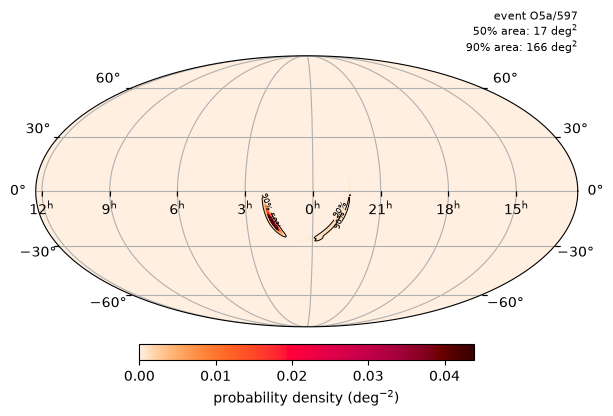

In [2]:
levels = (0.5, 0.9)
areas = {
    level: (products.credible_level <= level).sum() * pixel_area for level in levels
}

fig = plt.figure(figsize=(7.2, 4.4))
# Centred on the event: at the default centre one arc falls on the seam of
# the projection and is split between the two edges.
ax = fig.add_subplot(
    projection="astro hours mollweide", center=SkyCoord(center.ra, 0 * u.deg)
)
ax.grid()
image = ax.imshow_hpx((products.prob / pixel_area, "ICRS"), nested=True, cmap="cylon")
contours = ax.contour_hpx(
    (products.credible_level, "ICRS"),
    nested=True,
    levels=list(levels),
    colors="black",
    linewidths=0.7,
)
# Labelled on the contours themselves, as ligo-skymap-plot does, so the figure
# reads without a legend.
ax.clabel(
    contours,
    fmt={level: f"{level:.0%}" for level in levels},
    fontsize=6,
    inline=True,
)
fig.colorbar(
    image,
    ax=ax,
    orientation="horizontal",
    pad=0.05,
    shrink=0.6,
    label=r"probability density ($\mathrm{deg}^{-2}$)",
)
ax.text(
    1.0,
    1.0,
    "\n".join(
        [f"event {EXAMPLE_RUN}/{EXAMPLE_EVENT}"]
        + [rf"{level:.0%} area: {area:.0f} $\mathrm{{deg}}^2$"
           for level, area in areas.items()]
    ),
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=8,
)

for level, area in areas.items():
    print(f"{level:.0%} credible area: {area:.1f} deg2")

view centred on RA 4.1 deg, Dec -16.7 deg, radius 45.9 deg


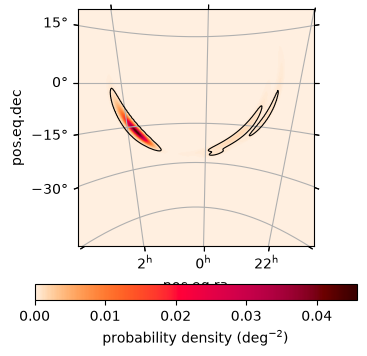

In [3]:
fig = plt.figure(figsize=(5.2, 4.2))
ax = fig.add_subplot(projection="astro zoom", center=center, radius=radius)
image = ax.imshow_hpx((products.prob / pixel_area, "ICRS"), nested=True, cmap="cylon")
ax.contour_hpx(
    (products.credible_level, "ICRS"),
    nested=True,
    levels=[0.9],
    colors="black",
    linewidths=0.8,
)
ax.grid()
fig.colorbar(
    image,
    ax=ax,
    label=r"probability density ($\mathrm{deg}^{-2}$)",
    orientation="horizontal",
    pad=0.12,
    shrink=0.8,
)

print(f"view centred on RA {center.ra.deg:.1f} deg, "
      f"Dec {center.dec.deg:+.1f} deg, radius {radius:.1f}")

## 2. What each direction would cost

Probability alone does not say where to point. Reaching SNR 5 on a kilonova
takes an exposure time that varies across the sky with Galactic extinction and
with the zodiacal and Cerenkov backgrounds ULTRASAT sees from its orbit. The
posterior alone is not enough to plan against; the exposure time is what makes
one direction more expensive than another.

The map below is a reference case: a source of absolute magnitude $-16$ at the
mean distance of this event, at the start of the window. Read it for how the
cost varies with direction, not for the exposures the plan uses. The scheduler
marginalizes over the distance posterior of each direction and over the 1.3 mag
scatter of the absolute magnitude, so it must reach the faint tail of that
distribution; its exposures are an order of magnitude longer than this map
suggests.

reference exposure inside the 90% region: 38 to 164 s
exposures the plan actually uses:         300 to 2388 s


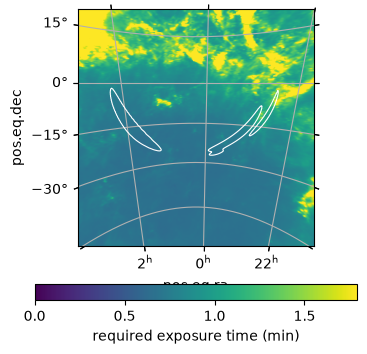

In [4]:
exptime = np.where(np.isfinite(products.exptime_min), products.exptime_min, np.nan)

# Over the whole sky the required time spans many orders of magnitude and
# diverges behind the Galactic plane, so the scale is set from this view alone.
sky = products.hpx.healpix_to_skycoord(np.arange(products.hpx.npix))
in_view = sky.separation(center) < radius
vmax = np.nanpercentile(exptime[in_view], 95)

fig = plt.figure(figsize=(5.2, 4.2))
ax = fig.add_subplot(projection="astro zoom", center=center, radius=radius)
image = ax.imshow_hpx((exptime, "ICRS"), nested=True, cmap="viridis", vmin=0, vmax=vmax)
ax.contour_hpx(
    (products.credible_level, "ICRS"),
    nested=True,
    levels=[0.9],
    colors="white",
    linewidths=0.8,
)
ax.grid()
fig.colorbar(
    image,
    ax=ax,
    label="required exposure time (min)",
    orientation="horizontal",
    pad=0.12,
    shrink=0.8,
)

inside = products.credible_level <= 0.9
print(f"reference exposure inside the 90% region: "
      f"{exptime[inside].min() * 60:.0f} to {exptime[inside].max() * 60:.0f} s")
print(f"exposures the plan actually uses:         "
      f"{plan.obs['duration'].min().to_value(u.s):.0f} to "
      f"{plan.obs['duration'].max().to_value(u.s):.0f} s")

## 3. Where and when it may look

The spacecraft cannot point anywhere at any time: the Sun, the Moon and the
Earth each exclude a moving part of the sky. What remains is the *field of
regard*, and it shifts over the six hours of the window.

For this event only the Earth constraint ever binds, and the reason is worth
spelling out. ULTRASAT sits in a geostationary orbit, which fixes it with
respect to the ground, not with respect to the stars. The sky map is drawn
against the stars, and in that frame the spacecraft goes round once a day, so
the Earth drifts across its sky at the sidereal rate of about 15 degrees an
hour, carrying its exclusion cone along. Six hours of that is enough to bring
the cone onto part of the localization near the end of the window. The Sun
moves about a degree a day and sits far outside its own limit, and the Moon
stays clear throughout.

The animation below shows the whole window. The curve that follows is the
same information integrated over the localization: the share of the posterior
probability reachable at each instant. A deadline matters for this reason. The
optimizer chooses from the part of the posterior that is reachable while the
kilonova is still bright, not from all of it.

In [5]:
times = plan.event_time + plan.delay + np.linspace(
    0, (plan.deadline - plan.delay).to_value(u.hour), 25
) * u.hour
observable = field_of_regard(plan, products.hpx, times)

never = ~observable.any(axis=0)
print(f"never observable: {never.mean() * 100:.0f}% of the sky, "
      f"holding {products.prob[never].sum():.3f} of the localization")

never observable: 41% of the sky, holding 0.000 of the localization


The same six hours as an animation, in the layout `m4opt animate` uses. The
pale blue region is what the Earth hides at each instant; watching it drift is
the clearest way to see why the curve below falls away near the deadline. The
darker region is what stays hidden for the whole window, which is the overlap
between the exclusion cone at the start and the one at the end. Two overlapping
discs meet at a point, so that region is lens-shaped with sharp corners; they
are geometry, not a drawing artefact. The
Sun, Moon and Earth are marked, the exposure-time map of step 2 is the grey
background, the observed fields appear in red as they are taken, and the
timeline tracks the probability and the area covered.

![Six hours of the O5a/597 plan](_static/plan_O5a_597_allsky.gif)

The file is kept in the repository rather than embedded in this notebook, and
is rebuilt with:

```
python scripts/figures/plan_figures.py \
    results/pixelpop/example/O5a/597_allsky.ecsv \
    --skymap results/pixelpop/example/O5a/597.fits \
    --layout allsky --step 10min --dpi 90 \
    --movie notebooks/_static/plan_O5a_597_allsky.gif
```

observable at the start of the window: 1.000
observable at the deadline:            0.835


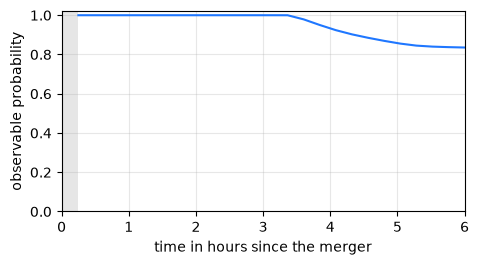

In [6]:
reachable = (products.prob * observable).sum(axis=1)

fig, ax = plt.subplots(figsize=(5.2, 2.6))
ax.plot(plan.hours(times), reachable, color="#1f77ff")
ax.set_xlabel("time in hours since the merger")
ax.set_ylabel("observable probability")
ax.set_xlim(0, plan.deadline.to_value(u.hour))
ax.set_ylim(0, 1.02)
ax.axvspan(0, plan.delay.to_value(u.hour), color="0.9", lw=0)
ax.grid(alpha=0.3)

print(f"observable at the start of the window: {reachable[0]:.3f}")
print(f"observable at the deadline:            {reachable[-1]:.3f}")

## 4. The pointings it may choose from

The scheduler does not aim anywhere it likes either. It picks from a fixed
sky grid, so that the problem stays a choice among a finite set of fields.
ULTRASAT has two: `allsky`, whose 361 pointings overlap, and `non-overlap`,
whose 240 tile the sky without redundancy. This plan used `allsky`.

Grey below: the candidates that fall within this view. Orange: the nine the
optimizer selected.

53 candidates in this view, 9 chosen, 18 exposures (2 visits each)


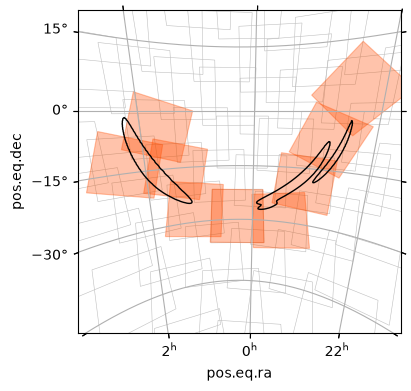

In [7]:
nearby = plan.candidates[plan.candidates.separation(center) < radius]

fig = plt.figure(figsize=(5.2, 4.2))
ax = fig.add_subplot(projection="astro zoom", center=center, radius=radius)
for region in footprint(plan.mission.fov, nearby, 0 * u.deg):
    ax.add_patch(
        region.to_pixel(ax.wcs).as_artist(
            facecolor="none", edgecolor="0.75", linewidth=0.4
        )
    )
for region in footprint(plan.mission.fov, plan.obs["target_coord"], plan.obs["roll"]):
    ax.add_patch(
        region.to_pixel(ax.wcs).as_artist(
            facecolor="#ff4d00",
            fill=True,
            alpha=0.18,
            edgecolor="#ff4d00",
            linewidth=0.8,
        )
    )
ax.contour_hpx(
    (products.credible_level, "ICRS"),
    nested=True,
    levels=[0.9],
    colors="black",
    linewidths=1.0,
)
ax.grid()

chosen = {(c.ra.deg, c.dec.deg) for c in plan.obs["target_coord"]}
print(f"{len(nearby)} candidates in this view, {len(chosen)} chosen, "
      f"{len(plan.obs)} exposures ({plan.visits} visits each)")

## 5. The plan, and what it covers

Each selected field is observed twice, 30 minutes apart, so that a transient
can be told from an artefact. The exposures are not equal: they run from 300 s
to 2388 s. The optimizer spends longer wherever the extra probability is worth
the time it takes, and falls back to the 300 s floor elsewhere.

The plan covers 1562 $\mathrm{deg}^2$, nine times the 90% credible region, and holds
0.988 of the posterior probability. Covering only the 90% region would have
left the remaining time unused; with a 204 $\mathrm{deg}^2$ field of view, extending
beyond it is nearly free.

footprint 1562 deg2 holding 0.988 of the probability
exposures from 300 s to 2388 s


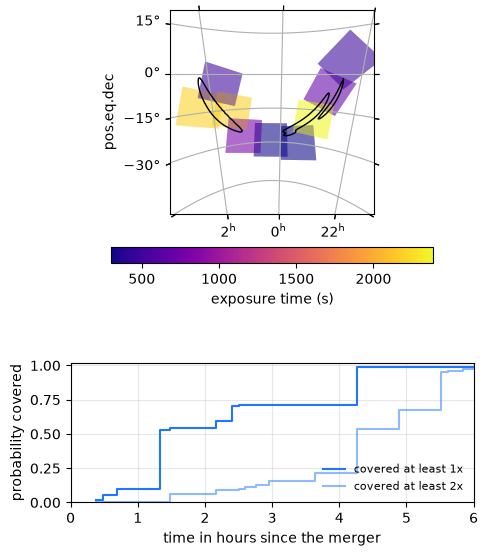

In [8]:
durations = plan.obs["duration"].to_value(u.s)
norm = plt.Normalize(durations.min(), durations.max())
cmap = plt.get_cmap("plasma")

fig, (ax_sky, ax_cov) = plt.subplots(
    2,
    1,
    figsize=(5.2, 6.4),
    gridspec_kw={"height_ratios": [2.0, 1.0], "hspace": 0.35},
    subplot_kw={},
)
ax_sky.remove()
ax_sky = fig.add_subplot(2, 1, 1, projection="astro zoom", center=center, radius=radius)
for region, duration in zip(
    footprint(plan.mission.fov, plan.obs["target_coord"], plan.obs["roll"]), durations
):
    ax_sky.add_patch(
        region.to_pixel(ax_sky.wcs).as_artist(
            facecolor=cmap(norm(duration)), fill=True, alpha=0.35, edgecolor="none"
        )
    )
ax_sky.contour_hpx(
    (products.credible_level, "ICRS"),
    nested=True,
    levels=[0.9],
    colors="black",
    linewidths=1.0,
)
ax_sky.grid()
fig.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=ax_sky,
    label="exposure time (s)",
    orientation="horizontal",
    pad=0.12,
    shrink=0.8,
)

hours = plan.hours(plan.obs["end_time"])
for visit in range(plan.visits):
    ax_cov.step(
        hours,
        products.covered_prob[:, visit],
        where="post",
        color="#1f77ff",
        alpha=1.0 - 0.5 * visit,
        label=f"covered at least {visit + 1}x",
    )
ax_cov.set_xlabel("time in hours since the merger")
ax_cov.set_ylabel("probability covered")
ax_cov.set_xlim(0, plan.deadline.to_value(u.hour))
ax_cov.set_ylim(0, 1.02)
ax_cov.legend(frameon=False, fontsize=8, loc="lower right")
ax_cov.grid(alpha=0.3)

print(f"footprint {products.covered_area[-1, 0]:.0f} deg2 "
      f"holding {products.covered_prob[-1, 0]:.3f} of the probability")
print(f"exposures from {durations.min():.0f} s to {durations.max():.0f} s")

## 6. What the objective is, and what the grid costs

The quantity the solver maximizes is

$$\text{objective} \;=\; \sum_i \mathrm{PROB}_i \, x_i ,$$

a sum over the pixels of the sky map, where $\mathrm{PROB}_i$ is the posterior
probability of direction $i$ and $x_i \in [0, 1]$ the probability of detecting
the kilonova in that direction. The objective is therefore itself a detection
probability, marginalized over direction, over distance and over absolute
magnitude.

What couples $x_i$ to the plan is a piecewise-linear constraint: claiming a
detection probability $x_i$ on a pixel requires at least $\tau_i(x_i)$ seconds
on the field covering it. M4OPT builds $\tau_i$ from the apparent-magnitude
distribution of that pixel, lognormal in distance and Gaussian in absolute
magnitude,

$$\mu_m = M + \tfrac{5}{\ln 10}\,\mu_{\log d} + 25, \qquad
\sigma_m = \sqrt{\sigma_M^2 + \left(\tfrac{5}{\ln 10}\,\sigma_{\log d}\right)^2},$$

and converts five quantiles of it into the exposure time each would need to
reach SNR 5. That conversion is where the instrument enters: throughput and
bandpass, point spread function, read noise, zodiacal light, Galactic
extinction, and for ULTRASAT the Cerenkov and trapped-particle background that
depends on where the spacecraft is in its orbit.

The pointing constraints are not part of the objective; they restrict what is
feasible. A field exists as a candidate only at the times when the Sun, Moon
and Earth avoidance of step 3 allows it, the slew times come from the mission
dynamics, and the delay, deadline, visit count and cadence fix the timeline.

`best_bound` came back equal to `objective_value`, which is CPLEX proving that
no plan over this grid does better. The time budget is saturated: 19 582 s of
exposure and 1 118 s of slewing exhaust the 20 700 s between the 15-minute
delay and the 6-hour deadline, to within a nanosecond.

Running the same event on the `non-overlap` grid shows what the grid itself is
worth. Fewer candidates mean more pointings to cover the same posterior, more
time lost to slewing, and a lower optimum. The coarser grid cannot even spend
the whole window.

In [9]:
rows = []
for grid in ("allsky", "non-overlap"):
    other = Plan.read(EXAMPLE / f"{EXAMPLE_EVENT}_{grid}.ecsv", skymap=str(SKYMAP))
    budget = {k: float(v.to_value(u.s)) for k, v in other.obs.meta["total_time"].items()}
    rows.append(
        (
            grid,
            len(other.candidates),
            len({(c.ra.deg, c.dec.deg) for c in other.obs["target_coord"]}),
            len(other.obs),
            other.obs.meta["objective_value"],
            budget["observe"],
            budget["slew"],
            budget["slack"],
        )
    )

header = ("grid", "cand.", "fields", "exp.", "objective", "observe", "slew", "slack")
print(f"{header[0]:12s}" + "".join(f"{h:>10s}" for h in header[1:]))
for row in rows:
    print(
        f"{row[0]:12s}{row[1]:10d}{row[2]:10d}{row[3]:10d}"
        f"{row[4]:10.4f}{row[5]:10.0f}{row[6]:10.0f}{row[7]:10.1f}"
    )

grid             cand.    fields      exp. objective   observe      slew     slack
allsky             361         9        18    0.9207     19582      1118      -0.0
non-overlap        240        12        24    0.8879     18375      1744     580.8


## 7. Two probabilities that are easy to confuse

The paper does not sum objective values. It sums
`detection_probability_known_position`, which answers a different question and
is computed afterwards, by `ugf-postprocess`, from the finished plan.

The objective marginalizes over where the source might be. The known-position
probability conditions on where it actually is: the simulated event has a true
position and a true distance, so postprocess keeps the observations whose
footprint contains that position, takes the deepest of them, converts its
limiting magnitude to an absolute magnitude at the true distance, and reads the
Gaussian CDF at that value. The instrument model is the same one; the
marginalization over sky and distance is gone.

That is why this event has an objective of 0.9207 but a known-position
probability of 0.969: knowing where the source is removes the risk that the
plan looked in the wrong direction.

Neither is a claim that the transient would have been *identified*. Both ask
whether it was above threshold. Telling a kilonova from a moving Solar System
object takes a detection in more than one visit, which is the stricter
criterion `get_detection_probability_two_visits` implements.

## Where to go next

`scripts/figures/plan_figures.py` draws the publication version of step 5 as a
still frame, in either a zoomed or an all-sky layout, and writes `.mp4` as
readily as the `.gif` shown earlier. Pass `--still plan.pdf` for the figure and
`--movie plan.mp4` for the animation.

`notebooks/kilonovae_detection_rate.ipynb` runs the same analysis over all
1975 events of the three O5 sub-periods and produces the numbers, tables and
figures of the paper.